# Content-Based Movie Recommender System
### A Beginner's Guide to Suggesting Movies Using Genres, Tags, and Natural Language Processing (NLP)

---

## 1. Text Preprocessing: Cleaning, Tokenization, and Stemming

### What is a Content-Based Recommender?
Imagine asking a friend for a movie recommendation similar to *Toy Story*. Your friend would think about what *Toy Story* is made of: it is an **animated family comedy** featuring **talking toys**, **Pixar**, and themes of **friendship**. Then, they would recommend movies with those same ingredients—like *Toy Story 2*, *Monsters, Inc.*, or *Finding Nemo*.

A **Content-Based Recommender** does the exact same thing mathematically. It examines the "content" (features) of items a user likes and finds other items with the most similar content. In our dataset, each movie is described by:
1. **Genres**: Official categories such as `Animation`, `Children`, `Comedy`, and `Adventure`.
2. **Tags**: Descriptive keywords added by real users, such as `toys come to life`, `pixar`, `friendship`, and `clever`.

---

### Why Can't Computers Read Raw Text Directly?
Computers do not understand language; they only understand numbers. Furthermore, raw user tags are messy and contain variations like:
- Different casing: `"Animation"`, `"animation"`, `"ANIMATION"`
- Punctuation & symbols: `"sci-fi"`, `"action!"`, `"family-friendly,"`
- Different grammatical forms of the same root word: `"adventures"`, `"adventurous"`, `"adventure"`

If we do not clean this text first, a computer treats `"Animation"` and `"animation"` as two completely separate concepts!

---

### The Three Core Steps of Text Preprocessing:
1. **Lowercasing**:
   - Converts all letters to lowercase so `"Comedy"` and `"comedy"` become identical.
2. **Removing Punctuation & Special Characters**:
   - Strips out symbols like `!`, `?`, `-`, commas, and delimiter pipes (`|`) so we only keep clean alphanumeric words.
3. **Tokenization and Stemming**:
   - **Tokenization**: Splitting a continuous sentence or tag phrase into individual word units called *tokens* (e.g., `"toys come to life"` becomes `['toys', 'come', 'to', 'life']`).
   - **Stemming**: Chopping off grammatical prefixes and suffixes to reduce words down to their root "stem" using algorithms like the **Porter Stemmer** (e.g., `"adventures"`, `"adventurous"`, and `"adventure"` all become `"adventur"`).

By stemming, we dramatically reduce vocabulary redundancy and ensure movies sharing related words are recognized as similar.

In [1]:
# ==============================================================================
# Cell 1 Code: Text Preprocessing Function, Data Loading, and Metadata Merging
# ==============================================================================

import sys
import subprocess

# Automatically verify and install required libraries in the active kernel
for pkg_name, import_name in [('seaborn', 'seaborn'), ('scikit-surprise', 'surprise')]:
    try:
        __import__(import_name)
    except ModuleNotFoundError:
        print(f"Installing '{pkg_name}' into active kernel...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg_name])


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from nltk.stem import PorterStemmer

# Set visualization aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

print("Step 1: Initializing text preprocessor and loading MovieLens metadata...")

# Initialize the Porter Stemmer for reducing words to their root stems
stemmer = PorterStemmer()

def clean_and_preprocess_text(text):
    """
    Cleans and preprocesses a raw text string for NLP:
    1. Lowercases all characters.
    2. Removes punctuation, digits, and special characters using regex.
    3. Tokenizes the text into individual words.
    4. Stems each word using PorterStemmer (filtering out very short words <= 2 letters).
    """
    if not isinstance(text, str):
        return ""
    
    # 1. Lowercase
    text = text.lower()
    
    # 2. Remove punctuation and non-alphabet characters
    text = re.sub(r'[^a-z\s]', ' ', text)
    
    # 3. Tokenize into individual words
    tokens = text.split()
    
    # 4. Stem each word and filter words with length > 2
    stemmed_tokens = [stemmer.stem(word) for word in tokens if len(word) > 2]
    
    # Return as a clean, space-separated string
    return " ".join(stemmed_tokens)

# Demonstrate how the cleaning function works on an example string
example_raw = "Toy Story (1995)! Genres: Animation|Children|Comedy. Tags: 'toys come to life', ADVENTURES, friendship!"
example_cleaned = clean_and_preprocess_text(example_raw)
print("\n--- Text Cleaning Demonstration ---")
print(f"Raw Input:     {example_raw}")
print(f"Cleaned Output: {example_cleaned}\n")

# Load movies.csv and tags.csv
print("Loading 'movies.csv' and 'tags.csv'...")
movies_df = pd.read_csv('movies.csv')
tags_df = pd.read_csv('tags.csv', usecols=['movieId', 'tag'])
tags_df['tag'] = tags_df['tag'].fillna('').astype(str)

# Select the top 10,000 movies with the richest tag metadata
# This provides rich recommendations while keeping the similarity matrix fast and memory-safe (~380 MB)
top_movie_ids = tags_df['movieId'].value_counts().head(10000).index
movies_subset = movies_df[movies_df['movieId'].isin(top_movie_ids)].copy().reset_index(drop=True)

# Aggregate all unique user tags for each movie into a single text string
tags_subset = tags_df[tags_df['movieId'].isin(top_movie_ids)]
movie_tags = tags_subset.groupby('movieId')['tag'].apply(lambda x: ' '.join(set(x))).reset_index()

# Merge movies with their aggregated tags
df = pd.merge(movies_subset, movie_tags, on='movieId', how='left')
df['tag'] = df['tag'].fillna('')

# Apply text cleaning to both genres and tags
print("Cleaning genres and user tags for the movie catalog...")
df['clean_genres'] = df['genres'].apply(clean_and_preprocess_text)
df['clean_tags'] = df['tag'].apply(clean_and_preprocess_text)

# Combine genres and tags into a single unified 'content' column
df['content'] = df['clean_genres'] + ' ' + df['clean_tags']

print(f"\nPreprocessing complete! Catalog ready with {len(df):,} movies.")
print("Sample preprocessed movie content:")
display(df[['movieId', 'title', 'genres', 'content']].head(3))

Step 1: Initializing text preprocessor and loading MovieLens metadata...

--- Text Cleaning Demonstration ---
Raw Input:     Toy Story (1995)! Genres: Animation|Children|Comedy. Tags: 'toys come to life', ADVENTURES, friendship!
Cleaned Output: toy stori genr anim children comedi tag toy come life adventur friendship

Loading 'movies.csv' and 'tags.csv'...


Cleaning genres and user tags for the movie catalog...



Preprocessing complete! Catalog ready with 10,000 movies.
Sample preprocessed movie content:


,movieId,title,genres,content
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,adventur anim children comedi fantasi hockey p...
1,2,Jumanji (1995),Adventure|Children|Fantasy,adventur children fantasi footwear first seri ...
2,5,Father of the Bride Part II (1995),Comedy,comedi comedi regret father pregnanc clv seque...


---

## 2. Converting Text into a Feature Matrix: TF-IDF & Cosine Similarity

### How Do We Turn Words into Math?
Once our text is clean and stemmed, we need a mathematical way to compare how "similar" Movie A is to Movie B. We accomplish this in two steps:

---

### Step 1: TF-IDF Vectorization (Term Frequency - Inverse Document Frequency)
TF-IDF converts a collection of words into a numerical feature vector. It measures how important a word is to a specific movie relative to the entire movie catalog:

1. **Term Frequency (TF)**: How often a word appears in a specific movie's content.
   - *Example*: If the word `"dinosaur"` appears 10 times in *Jurassic Park*, it is very important to that movie.
2. **Inverse Document Frequency (IDF)**: How rare or common that word is across the **entire catalog**.
   - Common words that appear in almost every movie (like `"good"`, `"great"`, `"film"`) get a low score because they do not help distinguish one movie from another.
   - Distinctive words that appear in only a few movies (like `"pixar"`, `"wizard"`, `"superhero"`, `"vampire"`) get a high score.
3. **TF-IDF Score = $	ext{TF} 	imes 	ext{IDF}$**:
   - Words with high TF-IDF scores are the unique "fingerprints" of that movie.

Each movie is now represented as a numerical vector in a 5,000-dimensional space (where each dimension corresponds to an important vocabulary word).

---

### Step 2: Cosine Similarity (Comparing Movie Vectors)
To find out how similar two movies are, we measure the angle between their two numeric vectors:
$$\text{Cosine Similarity}(A, B) = \cos(\theta) = \frac{A \cdot B}{\|A\| \|B\|}$$

- **Score = 1.0 (Angle = 0°)**: The two movies have identical content features.
- **Score = 0.0 (Angle = 90°)**: The two movies share zero common words or genres (completely unrelated).
- **Score between 0.2 and 0.8**: The movies share a substantial number of themes, genres, and descriptive keywords.

By calculating cosine similarity across our movie feature matrix, we generate a **Cosine Similarity Matrix**—a comprehensive similarity lookup table where cell `[i, j]` stores the similarity score between Movie `i` and Movie `j`.

In [2]:
# ==============================================================================
# Cell 2 Code: TF-IDF Vectorization and Cosine Similarity Matrix Computation
# ==============================================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import time

print("Step 2: Building the TF-IDF Feature Matrix and Cosine Similarity Matrix...")

t0 = time.time()

# 1. Initialize TfidfVectorizer
# - stop_words='english': Removes generic English words ('the', 'and', 'is')
# - max_features=5000: Retains the top 5,000 most informative vocabulary stems
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    dtype=np.float32
)

# 2. Fit and transform the clean movie content into a sparse TF-IDF matrix
tfidf_matrix = tfidf.fit_transform(df['content'])
tfidf_time = time.time() - t0

print(f"- TF-IDF matrix generated in {tfidf_time:.2f} seconds.")
print(f"- Matrix shape: {tfidf_matrix.shape[0]:,} movies x {tfidf_matrix.shape[1]:,} feature words")
print(f"- Vocabulary sample (first 10 features): {tfidf.get_feature_names_out()[:10].tolist()}")

# 3. Compute pairwise Cosine Similarity between all movies
t1 = time.time()
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
sim_time = time.time() - t1

print(f"\n- Cosine similarity matrix computed in {sim_time:.2f} seconds.")
print(f"- Similarity matrix shape: {cosine_sim.shape[0]:,} x {cosine_sim.shape[1]:,}")
print(f"- Memory usage of similarity matrix: {cosine_sim.nbytes / (1024**2):.1f} MB")

# Quick check: Compare Movie 0 with itself and with other movies
movie_0_title = df.loc[0, 'title']
print(f"\nVerification sanity check for '{movie_0_title}':")
print(f"- Similarity with itself: {cosine_sim[0, 0]:.4f} (Expected: 1.0000)")
print(f"- Similarity with Movie 1 ('{df.loc[1, 'title']}'): {cosine_sim[0, 1]:.4f}")

Step 2: Building the TF-IDF Feature Matrix and Cosine Similarity Matrix...


- TF-IDF matrix generated in 0.86 seconds.
- Matrix shape: 10,000 movies x 5,000 feature words
- Vocabulary sample (first 10 features): ['aaron', 'abandon', 'abduct', 'abil', 'aborigin', 'abort', 'abraham', 'abroad', 'abrupt', 'absent']



- Cosine similarity matrix computed in 3.61 seconds.
- Similarity matrix shape: 10,000 x 10,000
- Memory usage of similarity matrix: 381.5 MB

Verification sanity check for 'Toy Story (1995)':
- Similarity with itself: 1.0000 (Expected: 1.0000)
- Similarity with Movie 1 ('Jumanji (1995)'): 0.2604


---

## 3. The Recommendation Function: Finding Similar Movies

### How the `get_recommendations()` Function Works:
When a user asks: *"I loved Toy Story, what should I watch next?"*, our recommender executes the following logical steps:

1. **Title Lookup**:
   - Searches our catalog for the movie title (using case-insensitive matching).
   - Retrieves the unique index `idx` of the matched movie.
2. **Retrieve Similarity Scores**:
   - Accesses `cosine_sim[idx]`, which contains the similarity score of this movie against all other 10,000 movies in our catalog.
3. **Sort Scores in Descending Order**:
   - Sorts all movie scores from highest (most similar) to lowest (least similar).
4. **Filter Out the Query Movie Itself**:
   - The movie itself will always score a perfect `1.0` (at rank 0). We skip this first item so we do not recommend a movie to itself!
5. **Extract Top 10 Recommendations**:
   - Selects the next 10 highest-scoring movies and formats them into a clean, readable table showing:
     - Movie Title
     - Genres
     - Exact Similarity Score (0.0 to 1.0)

In [3]:
# ==============================================================================
# Cell 3 Code: Build and Test the get_recommendations(movie_title) Function
# ==============================================================================

def get_recommendations(movie_title, top_n=10, cosine_sim=cosine_sim, df=df):
    """
    Returns the top_n most similar movies to a given movie title based on content similarity.
    
    Parameters:
        movie_title (str): Title or partial title of the target movie.
        top_n (int): Number of similar movie recommendations to return (default: 10).
        cosine_sim (ndarray): Precomputed pairwise cosine similarity matrix.
        df (DataFrame): Movie catalog DataFrame containing 'title' and 'genres'.
        
    Returns:
        DataFrame: Top N recommended movies with their title, genres, and similarity scores.
    """
    # 1. Search for title matches (case-insensitive)
    matches = df[df['title'].str.lower().str.contains(movie_title.lower(), regex=False)]
    
    if len(matches) == 0:
        print(f"Error: Movie title '{movie_title}' was not found in the catalog.")
        return None
    
    # Retrieve index and exact title of the first matching movie
    idx = matches.index[0]
    matched_title = df.loc[idx, 'title']
    print(f"Generating Top {top_n} recommendations for: '{matched_title}'")
    
    # 2. Get pairwise similarity scores of all movies with this movie
    sim_scores = list(enumerate(cosine_sim[idx]))
    
    # 3. Sort movies based on similarity scores in descending order
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    
    # 4. Skip index 0 (itself) and select the top_n movies
    top_matches = sim_scores[1:top_n + 1]
    
    # 5. Extract movie indices and similarity scores
    movie_indices = [item[0] for item in top_matches]
    scores = [item[1] for item in top_matches]
    
    # 6. Format into a clean results DataFrame
    recommendations = df.loc[movie_indices, ['title', 'genres']].copy().reset_index(drop=True)
    recommendations.insert(0, 'Rank', range(1, top_n + 1))
    recommendations['Similarity Score'] = [f"{s:.4f}" for s in scores]
    
    return recommendations

# ------------------------------------------------------------------------------
# Test Recommendations on 3 Famous Movies Across Different Genres
# ------------------------------------------------------------------------------

# Test 1: Animated Family Classic
print("=" * 75)
print("TEST 1: ANIMATED FAMILY MOVIE")
print("=" * 75)
display(get_recommendations('Toy Story', top_n=10))

# Test 2: Action / Sci-Fi
print("\n" + "=" * 75)
print("TEST 2: SCI-FI / ACTION MOVIE")
print("=" * 75)
display(get_recommendations('Matrix', top_n=10))

# Test 3: Fantasy / Adventure
print("\n" + "=" * 75)
print("TEST 3: FANTASY / ADVENTURE MOVIE")
print("=" * 75)
display(get_recommendations('Jumanji', top_n=10))

TEST 1: ANIMATED FAMILY MOVIE
Generating Top 10 recommendations for: 'Toy Story (1995)'


,Rank,title,genres,Similarity Score
0,1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.6572
1,2,Toy Story 4 (2019),Adventure|Animation|Children|Comedy,0.6525
2,3,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.6289
3,4,Toy Story That Time Forgot (2014),Animation|Children,0.5157
4,5,Lamp Life (2020),Animation|Children|Comedy,0.4838
5,6,Small Soldiers (1998),Animation|Children|Fantasy|War,0.4678
6,7,Toy Story Toons: Partysaurus Rex (2012),Animation|Children|Comedy,0.4606
7,8,"Indian in the Cupboard, The (1995)",Adventure|Children|Fantasy,0.4088
8,9,Child's Play (2019),Comedy|Horror,0.4023
9,10,Dolls (1987),Horror,0.3988



TEST 2: SCI-FI / ACTION MOVIE
Generating Top 10 recommendations for: 'Matrix, The (1999)'


,Rank,title,genres,Similarity Score
0,1,"Matrix Reloaded, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,0.5924
1,2,"Matrix Revolutions, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,0.5770
2,3,"Animatrix, The (2003)",Action|Animation|Drama|Sci-Fi,0.4353
3,4,The Matrix Resurrections (2021),Action|Adventure|Sci-Fi,0.4290
4,5,Tron (1982),Action|Adventure|Sci-Fi,0.4088
5,6,Terminator 2: Judgment Day (1991),Action|Sci-Fi,0.4038
6,7,"Thirteenth Floor, The (1999)",Drama|Sci-Fi|Thriller,0.3727
7,8,Total Recall (1990),Action|Adventure|Sci-Fi|Thriller,0.3715
8,9,"Terminator, The (1984)",Action|Sci-Fi|Thriller,0.3714
9,10,Tron: Legacy (2010),Action|Adventure|Sci-Fi|IMAX,0.3633



TEST 3: FANTASY / ADVENTURE MOVIE
Generating Top 10 recommendations for: 'Jumanji (1995)'


,Rank,title,genres,Similarity Score
0,1,Jumanji: Welcome to the Jungle (2017),Action|Adventure|Children,0.3457
1,2,Terminator 2: Judgment Day (1991),Action|Sci-Fi,0.3451
2,3,Fantastic Beasts and Where to Find Them (2016),Fantasy,0.3363
3,4,Back to the Future (1985),Adventure|Comedy|Sci-Fi,0.3160
4,5,Back to the Future Part II (1989),Adventure|Comedy|Sci-Fi,0.3139
5,6,Mad Max (1979),Action|Adventure|Sci-Fi,0.2980
6,7,The Addams Family (2019),Animation|Children|Comedy|Fantasy|Horror,0.2928
7,8,Last Action Hero (1993),Action|Adventure|Comedy|Fantasy,0.2923
8,9,Spider-Man: Into the Spider-Verse (2018),Action|Adventure|Animation|Sci-Fi,0.2831
9,10,"SpongeBob Movie: Sponge Out of Water, The (2015)",Adventure|Animation|Children|Comedy,0.2823


---

## 4. Visual Charts for Content Features and Model Mechanics

### Why Seeing Visual Charts Helps Us Understand the Recommender:
To confirm that our recommendation system is working effectively and to inspect its inner mechanics, we visualize three key components:

1. **Plot 4: Vocabulary Size Reduction After Cleaning**:
   - Compares the total number of unique words before cleaning (raw tokens), after lowercasing and punctuation stripping, and after stemming.
   - *Why it matters*: Demonstrates how NLP text preprocessing consolidates thousands of duplicate word variations into compact root stems, eliminating data sparsity.

2. **Plot 5: Histogram of Movie Similarity Scores**:
   - Shows the distribution of similarity scores across pairwise movie comparisons.
   - *Why it matters*: Demonstrates that the vast majority of movie pairs share almost no similarity (scores close to 0.0), while only a tiny, selective fraction of movies achieve high similarity (>0.3). This proves the recommender has sharp discrimination and is not recommending random items.

3. **Plot 6: Bar Chart of the Top 20 Most Frequent Words in Movie Tags**:
   - Highlights the 20 most popular descriptive keywords and concepts across our entire movie catalog.
   - *Why it matters*: Reveals the dominant thematic categories (e.g., `comedy`, `action`, `dramat`, `dark`, `base`, `seri`) that guide recommendations.

/var/folders/t5/r8ysdt5x2j95xb0t10svdd7r0000gn/T/ipykernel_1980/483082849.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=stages, y=vocab_sizes, palette=colors)


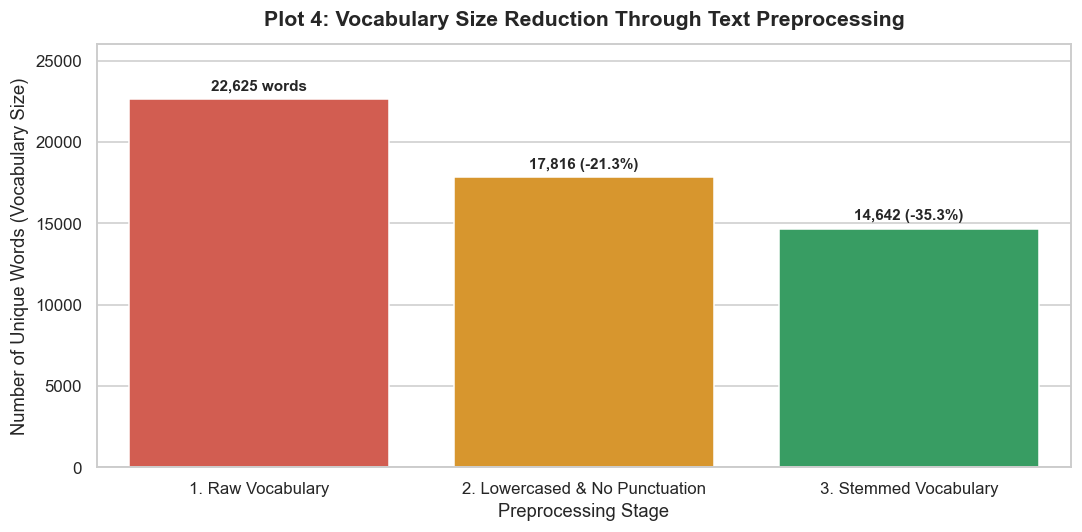

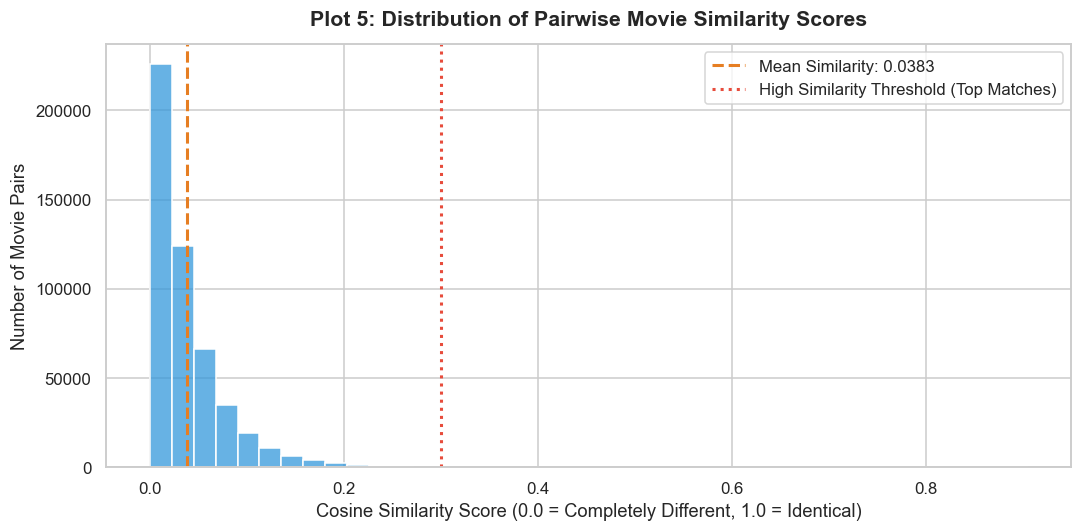

/var/folders/t5/r8ysdt5x2j95xb0t10svdd7r0000gn/T/ipykernel_1980/483082849.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(


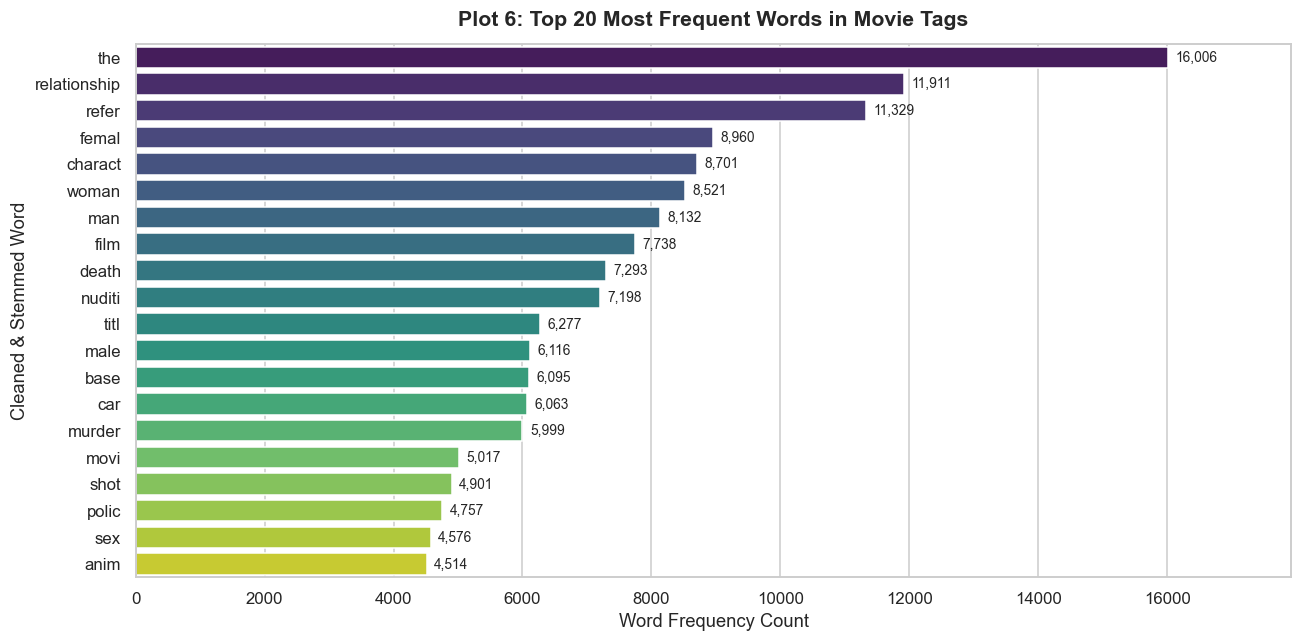

All 3 diagnostic plots generated successfully!


In [4]:
# ==============================================================================
# Cell 4 Code: Generate 3 Visual Plots for Content Features
# ==============================================================================

# ------------------------------------------------------------------------------
# Plot 4: Vocabulary Size Reduction After Cleaning
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))

# Calculate vocabulary sizes at each preprocessing stage from a sample of 1,000 movie tag sets
sample_texts = df['tag'].head(1000).dropna().tolist()

# 1. Raw unique tokens (split by whitespace)
raw_vocab = set()
for t in sample_texts:
    raw_vocab.update(t.split())

# 2. Lowercased and punctuation removed tokens
cleaned_vocab = set()
for t in sample_texts:
    words = re.findall(r'[a-zA-Z]+', t.lower())
    cleaned_vocab.update([w for w in words if len(w) > 2])

# 3. Stemmed tokens
stemmed_vocab = set()
for word in cleaned_vocab:
    stemmed_vocab.add(stemmer.stem(word))

stages = ['1. Raw Vocabulary', '2. Lowercased & No Punctuation', '3. Stemmed Vocabulary']
vocab_sizes = [len(raw_vocab), len(cleaned_vocab), len(stemmed_vocab)]
colors = ['#e74c3c', '#f39c12', '#27ae60']

ax1 = sns.barplot(x=stages, y=vocab_sizes, palette=colors)

plt.title('Plot 4: Vocabulary Size Reduction Through Text Preprocessing', fontsize=14, fontweight='bold', pad=12)
plt.ylabel('Number of Unique Words (Vocabulary Size)', fontsize=12)
plt.xlabel('Preprocessing Stage', fontsize=12)

# Annotate each bar with the count and percentage reduction
initial_size = vocab_sizes[0]
for i, p in enumerate(ax1.patches):
    height = p.get_height()
    reduction = ((initial_size - height) / initial_size) * 100
    label = f"{int(height):,} words" if i == 0 else f"{int(height):,} (-{reduction:.1f}%)"
    ax1.annotate(
        label,
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points'
    )

plt.ylim(0, max(vocab_sizes) * 1.15)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Plot 5: Histogram of Movie Similarity Scores
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))

# Sample 100,000 off-diagonal similarity scores to inspect the score distribution
# Exclude diagonal elements (similarity of movie with itself = 1.0)
np.random.seed(42)
sampled_indices = np.random.choice(cosine_sim.shape[0], size=1000, replace=False)
sub_matrix = cosine_sim[sampled_indices, :][:, sampled_indices]
# Extract upper triangle without diagonal
triu_indices = np.triu_indices_from(sub_matrix, k=1)
sample_similarity_scores = sub_matrix[triu_indices]

# Plot histogram of similarity scores
sns.histplot(
    sample_similarity_scores,
    bins=40,
    color='#3498db',
    edgecolor='white'
)

plt.title('Plot 5: Distribution of Pairwise Movie Similarity Scores', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Cosine Similarity Score (0.0 = Completely Different, 1.0 = Identical)', fontsize=12)
plt.ylabel('Number of Movie Pairs', fontsize=12)

# Add reference lines for mean and recommendation threshold
mean_sim = np.mean(sample_similarity_scores)
plt.axvline(mean_sim, color='#e67e22', linestyle='--', linewidth=2, label=f'Mean Similarity: {mean_sim:.4f}')
plt.axvline(0.3, color='#e74c3c', linestyle=':', linewidth=2, label='High Similarity Threshold (Top Matches)')
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Plot 6: Bar Chart of the Top 20 Most Frequent Words in Movie Tags
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# Count words across all cleaned content / tags in the dataset
all_tag_words = []
for text in df['clean_tags']:
    all_tag_words.extend(text.split())

word_counts = Counter(all_tag_words).most_common(20)
top_words = [item[0] for item in word_counts]
counts = [item[1] for item in word_counts]

ax3 = sns.barplot(
    x=counts,
    y=top_words,
    palette='viridis'
)

plt.title('Plot 6: Top 20 Most Frequent Words in Movie Tags', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Word Frequency Count', fontsize=12)
plt.ylabel('Cleaned & Stemmed Word', fontsize=12)

# Annotate each bar with the frequency count
for p in ax3.patches:
    width = p.get_width()
    ax3.annotate(
        f"{int(width):,}",
        (width, p.get_y() + p.get_height() / 2.),
        ha='left', va='center', fontsize=9, xytext=(5, 0), textcoords='offset points'
    )

plt.xlim(0, max(counts) * 1.12)
plt.tight_layout()
plt.show()

print("All 3 diagnostic plots generated successfully!")